In [98]:
import pandas as pd
import numpy as np

1) Import Preprocessed dataset - Null values are replaced
2) Find information about dataset; split quan and qual
3) Find outliers in quan - both lesser layer outliers and higher layer outliers
4) Replace the outliers
5) Check for invalid data in numerical and categorical columns; change text in numerical to valid numerical; replace invalid data to valid data in
categorical columns
7) check for duplicated rows and remove them
8) Copy the cleaned data to a new dataset
9) Do Univariate Analysis for quan and qual
10) Do Bivariate Analysis for quan and qual

1) Import Preprocessed dataset

In [99]:
dataset = pd.read_csv("PreprocessedKidneyDisease.csv")

In [100]:
dataset

,id,age,bp,sg,al,su,bgr,bu,sc,sod,...,pc,pcc,ba,htn,dm,cad,appet,pe,ane,classification
0,0.0,48.0,80.0,1.020,1.0,0.0,121.000000,36.0,1.2,137.528754,...,1,0,0,1,1,0,0,0,0,0
1,1.0,7.0,50.0,1.020,4.0,0.0,148.036517,18.0,0.8,137.528754,...,1,0,0,0,0,0,0,0,0,0
2,2.0,62.0,80.0,1.010,2.0,3.0,423.000000,53.0,1.8,137.528754,...,1,0,0,0,1,0,1,0,1,0
3,3.0,48.0,70.0,1.005,4.0,0.0,117.000000,56.0,3.8,111.000000,...,0,1,0,1,0,0,1,1,1,0
4,4.0,51.0,80.0,1.010,2.0,0.0,106.000000,26.0,1.4,137.528754,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,395.0,55.0,80.0,1.020,0.0,0.0,140.000000,49.0,0.5,150.000000,...,1,0,0,0,0,0,0,0,0,1
396,396.0,42.0,70.0,1.025,0.0,0.0,75.000000,31.0,1.2,141.000000,...,1,0,0,0,0,0,0,0,0,1
397,397.0,12.0,80.0,1.020,0.0,0.0,100.000000,26.0,0.6,137.000000,...,1,0,0,0,0,0,0,0,0,1
398,398.0,17.0,60.0,1.025,0.0,0.0,114.000000,50.0,1.0,135.000000,...,1,0,0,0,0,0,0,0,0,1


In [101]:
print(dataset.columns.tolist())

['id', 'age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'classification']


In [102]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    float64
 1   age             400 non-null    float64
 2   bp              400 non-null    float64
 3   sg              400 non-null    float64
 4   al              400 non-null    float64
 5   su              400 non-null    float64
 6   bgr             400 non-null    float64
 7   bu              400 non-null    float64
 8   sc              400 non-null    float64
 9   sod             400 non-null    float64
 10  pot             400 non-null    float64
 11  hemo            400 non-null    float64
 12  pcv             400 non-null    float64
 13  wc              400 non-null    float64
 14  rc              400 non-null    float64
 15  rbc             400 non-null    int64  
 16  pc              400 non-null    int64  
 17  pcc             400 non-null    int

Finding numeric column to have text and data type as object - Handling the numeric column

In [103]:
dataset["pcv"].dtype

dtype('float64')

In [104]:
dataset["pcv"].value_counts()

pcv
38.636364    70
52.000000    21
41.000000    21
48.000000    19
44.000000    19
40.000000    16
43.000000    14
42.000000    13
45.000000    13
36.000000    12
33.000000    12
28.000000    12
50.000000    12
32.000000    12
37.000000    11
34.000000    11
46.000000     9
30.000000     9
29.000000     9
35.000000     9
31.000000     8
24.000000     7
39.000000     7
26.000000     6
38.000000     5
53.000000     4
51.000000     4
49.000000     4
47.000000     4
54.000000     4
25.000000     3
22.000000     3
27.000000     3
19.000000     2
23.000000     2
0.000000      2
15.000000     1
21.000000     1
17.000000     1
20.000000     1
18.000000     1
9.000000      1
16.000000     1
14.000000     1
Name: count, dtype: int64

In [105]:
dataset["wc"].dtype

dtype('float64')

In [106]:
dataset["wc"].value_counts()

wc
8377.627119     105
9800.000000      11
6700.000000      10
9600.000000       9
7200.000000       9
               ... 
19100.000000      1
0.000000          1
12300.000000      1
16700.000000      1
2600.000000       1
Name: count, Length: 91, dtype: int64

In [107]:
dataset["rc"].dtype

dtype('float64')

In [108]:
dataset["rc"].value_counts()

rc
4.69    130
5.20     18
4.50     16
4.90     14
4.70     11
3.90     10
5.00     10
4.80     10
4.60      9
3.40      9
5.90      8
3.70      8
6.10      8
5.50      8
5.40      7
5.30      7
5.80      7
3.80      7
4.20      6
4.30      6
4.00      6
5.60      6
5.10      5
6.20      5
6.40      5
5.70      5
6.50      5
4.40      5
3.20      5
4.10      5
6.00      4
3.60      4
6.30      4
3.30      3
3.00      3
3.50      3
2.50      2
2.60      2
2.80      2
2.90      2
2.70      2
2.10      2
3.10      2
0.00      1
2.30      1
2.40      1
8.00      1
Name: count, dtype: int64

In [109]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    float64
 1   age             400 non-null    float64
 2   bp              400 non-null    float64
 3   sg              400 non-null    float64
 4   al              400 non-null    float64
 5   su              400 non-null    float64
 6   bgr             400 non-null    float64
 7   bu              400 non-null    float64
 8   sc              400 non-null    float64
 9   sod             400 non-null    float64
 10  pot             400 non-null    float64
 11  hemo            400 non-null    float64
 12  pcv             400 non-null    float64
 13  wc              400 non-null    float64
 14  rc              400 non-null    float64
 15  rbc             400 non-null    int64  
 16  pc              400 non-null    int64  
 17  pcc             400 non-null    int

# Checking if the numerical columns have numeric datatype only and categorical columns have invalid data

In [110]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    float64
 1   age             400 non-null    float64
 2   bp              400 non-null    float64
 3   sg              400 non-null    float64
 4   al              400 non-null    float64
 5   su              400 non-null    float64
 6   bgr             400 non-null    float64
 7   bu              400 non-null    float64
 8   sc              400 non-null    float64
 9   sod             400 non-null    float64
 10  pot             400 non-null    float64
 11  hemo            400 non-null    float64
 12  pcv             400 non-null    float64
 13  wc              400 non-null    float64
 14  rc              400 non-null    float64
 15  rbc             400 non-null    int64  
 16  pc              400 non-null    int64  
 17  pcc             400 non-null    int

Checking if all the numerical columns have only numerical data and replacing non-numerical data to numerical data

In [111]:
dataset["age"].value_counts()

age
60.0    19
65.0    17
48.0    12
50.0    12
55.0    12
        ..
90.0     1
27.0     1
83.0     1
4.0      1
79.0     1
Name: count, Length: 77, dtype: int64

In [112]:
dataset["bp"].value_counts()

bp
80.000000     116
70.000000     112
60.000000      71
90.000000      53
100.000000     25
76.469072      12
50.000000       5
110.000000      3
140.000000      1
180.000000      1
120.000000      1
Name: count, dtype: int64

In [113]:
dataset["sg"].value_counts()

sg
1.020000    106
1.010000     84
1.025000     81
1.015000     75
1.017408     47
1.005000      7
Name: count, dtype: int64

In [114]:
dataset["al"].value_counts()

al
0.000000    199
1.016949     46
1.000000     44
2.000000     43
3.000000     43
4.000000     24
5.000000      1
Name: count, dtype: int64

In [115]:
dataset["su"].value_counts()

su
0.000000    290
0.450142     49
2.000000     18
3.000000     14
4.000000     13
1.000000     13
5.000000      3
Name: count, dtype: int64

In [116]:
dataset["bgr"].value_counts()

bgr
148.036517    44
99.000000     10
93.000000      9
100.000000     9
107.000000     8
              ..
380.000000     1
288.000000     1
84.000000      1
256.000000     1
309.000000     1
Name: count, Length: 147, dtype: int64

In [117]:
dataset["bu"].value_counts()

bu
57.425722     19
46.000000     15
25.000000     13
19.000000     11
40.000000     10
              ..
322.000000     1
162.000000     1
235.000000     1
85.000000      1
165.000000     1
Name: count, Length: 119, dtype: int64

In [118]:
dataset["sc"].value_counts()

sc
1.2     40
1.1     24
0.5     23
1.0     23
0.9     22
        ..
9.2      1
13.8     1
9.7      1
24.0     1
0.4      1
Name: count, Length: 85, dtype: int64

In [119]:
dataset["sod"].value_counts()

sod
137.528754    87
135.000000    40
140.000000    25
141.000000    22
139.000000    21
142.000000    20
138.000000    20
137.000000    19
150.000000    17
136.000000    17
147.000000    13
145.000000    11
146.000000    10
132.000000    10
144.000000     9
131.000000     9
133.000000     8
130.000000     7
134.000000     6
143.000000     4
127.000000     3
124.000000     3
114.000000     2
125.000000     2
120.000000     2
113.000000     2
128.000000     2
122.000000     2
104.000000     1
129.000000     1
115.000000     1
4.500000       1
163.000000     1
111.000000     1
126.000000     1
Name: count, dtype: int64

In [120]:
dataset["pot"].value_counts()

pot
4.627244     88
3.500000     30
5.000000     30
4.900000     27
4.700000     17
4.800000     16
4.000000     14
4.100000     14
4.400000     14
3.900000     14
3.800000     14
4.200000     14
4.500000     13
4.300000     12
3.700000     12
3.600000      8
4.600000      7
3.400000      5
5.200000      5
5.700000      4
5.300000      4
6.300000      3
5.400000      3
2.900000      3
3.300000      3
5.500000      3
3.200000      3
2.500000      2
5.900000      2
5.800000      2
5.600000      2
3.000000      2
6.500000      2
7.600000      1
39.000000     1
6.400000      1
47.000000     1
5.100000      1
2.800000      1
2.700000      1
6.600000      1
Name: count, dtype: int64

In [121]:
dataset["hemo"].value_counts()

hemo
12.526437    52
15.000000    16
10.900000     8
13.600000     7
13.000000     7
             ..
6.800000      1
8.500000      1
7.300000      1
12.800000     1
17.600000     1
Name: count, Length: 116, dtype: int64

Checking for any invalid data in categorical columns and replacing them with valid categorical data

In [122]:
dataset["rbc"].value_counts()

rbc
1    353
0     47
Name: count, dtype: int64

In [123]:
dataset["pc"].value_counts()

pc
1    324
0     76
Name: count, dtype: int64

In [124]:
dataset["pcc"].value_counts()

pcc
0    358
1     42
Name: count, dtype: int64

In [125]:
dataset["ba"].value_counts()

ba
0    378
1     22
Name: count, dtype: int64

In [126]:
dataset["htn"].value_counts()

htn
0    253
1    147
Name: count, dtype: int64

In [127]:
dataset["dm"].value_counts()

dm
0    263
1    137
Name: count, dtype: int64

In [128]:
dataset["cad"].value_counts()

cad
0    366
1     34
Name: count, dtype: int64

In [129]:
dataset["appet"].value_counts()

appet
0    318
1     82
Name: count, dtype: int64

In [130]:
dataset["pe"].value_counts()

pe
0    324
1     76
Name: count, dtype: int64

In [131]:
dataset["ane"].value_counts()

ane
0    340
1     60
Name: count, dtype: int64

In [132]:
dataset["classification"].value_counts()

classification
0    250
1    150
Name: count, dtype: int64

# Checking if there is any null value

In [133]:
dataset.isnull().sum()

id                0
age               0
bp                0
sg                0
al                0
su                0
bgr               0
bu                0
sc                0
sod               0
pot               0
hemo              0
pcv               0
wc                0
rc                0
rbc               0
pc                0
pcc               0
ba                0
htn               0
dm                0
cad               0
appet             0
pe                0
ane               0
classification    0
dtype: int64

# Finding if there are duplicate records

In [134]:
dataset[dataset.duplicated()]

,id,age,bp,sg,al,su,bgr,bu,sc,sod,...,pc,pcc,ba,htn,dm,cad,appet,pe,ane,classification


No Duplicates

In [135]:
dataset.shape

(400, 26)

Finding Outliers and Replacing Outliers - Both Lesser layer and Higher layer

In [136]:
def QuanQual(dataset):
    quan = []
    qual = []
    for columnName in dataset.columns:
        #print(columnName)
        if(dataset[columnName].dtypes=='O'):
            qual.append(columnName)
        else:
            quan.append(columnName)
    return quan, qual

In [137]:
quan, qual = QuanQual(dataset)

In [138]:
quan

['id',
 'age',
 'bp',
 'sg',
 'al',
 'su',
 'bgr',
 'bu',
 'sc',
 'sod',
 'pot',
 'hemo',
 'pcv',
 'wc',
 'rc',
 'rbc',
 'pc',
 'pcc',
 'ba',
 'htn',
 'dm',
 'cad',
 'appet',
 'pe',
 'ane',
 'classification']

In [42]:
qual

[]

Creating a Dataframe to see all the details of data including outliers

In [183]:
import pandas as pd
only_quan = clean_dataset[["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wc", "rc"]]

In [181]:
df_outliers = pd.DataFrame(index = 
                           ["Mean", "Median", "Mode", "Q1:25%", "Q2:50%", "Q3:75%", "99%", "Q4:100%", "IQR", "1.5Rule","Lesser", "Greater", 
                            "Min", "Max" ], 
                            columns = ["age", "bp","sg", "al", "su", "bgr", "bu","sc", "sod", "pot","hemo","pcv","wc","rc"])

In [182]:
df_outliers

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc
Mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Median,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mode,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q1:25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q2:50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q3:75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
99%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q4:100%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IQR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1.5Rule,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [184]:
for columnName in only_quan:
    df_outliers.loc["Mean",columnName ] = dataset[columnName].mean()
    df_outliers.loc["Median", columnName] = dataset[columnName].median()
    df_outliers.loc["Mode", columnName]=dataset[columnName].mode()[0]
    df_outliers.loc["Q1:25%", columnName] = dataset.describe()[columnName]["25%"]
    df_outliers.loc["Q2:50%", columnName] = dataset.describe()[columnName]["50%"]
    df_outliers.loc["Q3:75%", columnName]= dataset.describe()[columnName]["75%"]
    df_outliers.loc["99%", columnName] = np.percentile(dataset[columnName], 99)
    df_outliers.loc["Q4:100%", columnName] = dataset.describe()[columnName]["max"]
    df_outliers.loc["IQR", columnName] = df_outliers.loc["Q3:75%", columnName] - df_outliers.loc["Q1:25%", columnName]
    df_outliers.loc["1.5Rule", columnName] = 1.5*df_outliers.loc["IQR", columnName]
    df_outliers.loc["Lesser", columnName] = df_outliers.loc["Q1:25%", columnName] - df_outliers.loc["1.5Rule", columnName]
    df_outliers.loc["Greater", columnName] = df_outliers.loc["Q3:75%", columnName] + df_outliers.loc["1.5Rule", columnName]
    df_outliers.loc["Min", columnName] = dataset[columnName].min()
    df_outliers.loc["Max", columnName] = dataset[columnName].max()


In [185]:
df_outliers

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc
Mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437,38.636364,8377.627119,4.69
Median,54.0,78.234536,1.017408,1.0,0.0,126.0,44.0,1.4,137.528754,4.627244,12.526437,38.636364,8377.627119,4.69
Mode,60.0,80.0,1.02,0.0,0.0,148.036517,57.425722,1.2,137.528754,4.627244,12.526437,38.636364,8377.627119,4.69
Q1:25%,42.0,70.0,1.015,0.0,0.0,101.0,27.0,0.9,135.0,4.0,10.875,34.0,6900.0,4.5
Q2:50%,54.0,78.234536,1.017408,1.0,0.0,126.0,44.0,1.4,137.528754,4.627244,12.526437,38.636364,8377.627119,4.69
Q3:75%,64.0,80.0,1.02,2.0,0.450142,150.0,61.75,3.072454,141.0,4.8,14.625,44.0,9400.0,5.1
99%,80.01,110.0,1.025,4.0,4.0,425.22,235.06,18.159,150.0,6.501,17.601,53.01,16722.0,6.5
Q4:100%,90.0,180.0,1.025,5.0,5.0,490.0,391.0,76.0,163.0,47.0,17.8,54.0,26400.0,8.0
IQR,22.0,10.0,0.005,2.0,0.450142,49.0,34.75,2.172454,6.0,0.8,3.75,10.0,2500.0,0.6
1.5Rule,33.0,15.0,0.0075,3.0,0.675214,73.5,52.125,3.258681,9.0,1.2,5.625,15.0,3750.0,0.9


Finding outliers - Both Lesser and Higher

In [188]:
def Finding_outliers(df_outliers, only_quan):
    lesser = []
    greater = []

    for columnName in only_quan:
        if df_outliers[columnName]["Min"] < df_outliers[columnName]["Lesser"]:
            lesser.append(columnName)

        if df_outliers[columnName]["Max"] > df_outliers[columnName]["Greater"]:
            greater.append(columnName)

    return lesser, greater


In [189]:
Lesser, Greater = Finding_outliers(df_outliers, only_quan)
print("Lesser:", Lesser)
print("Greater:", Greater)


Lesser: ['age', 'bp', 'sg', 'bgr', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc']
Greater: ['bp', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'wc', 'rc']


Lesser Layer Outliers below: Cross-checking with the df_outliers dataframe

In [190]:
print(dataset["age"].min())
print(df_outliers["age"]["Lesser"])

2.0
9.0


In [191]:
print(dataset["bp"].min())
print(df_outliers["bp"]["Lesser"])


50.0
55.0


In [192]:
print(dataset["sg"].min())
print(df_outliers["sg"]["Lesser"])


1.005
1.0074999999999998


In [193]:
print(dataset["bgr"].min())
print(df_outliers["bgr"]["Lesser"])


22.0
27.5


In [194]:
print(dataset["sod"].min())
print(df_outliers["sod"]["Lesser"])


4.5
126.0


In [195]:
print(dataset["pot"].min())
print(df_outliers["pot"]["Lesser"])


2.5
2.8000000000000003


In [196]:
print(dataset["hemo"].min())
print(df_outliers["hemo"]["Lesser"])


3.1
5.25


In [197]:
print(dataset["pcv"].min())
print(df_outliers["pcv"]["Lesser"])


0.0
19.0


In [198]:
print(dataset["wc"].min())
print(df_outliers["wc"]["Lesser"])


0.0
3150.0


In [199]:
print(dataset["rc"].min())
print(df_outliers["rc"]["Lesser"])


0.0
3.6000000000000005


Higher Layer outliers below: cross-checking with the df_outliers dataframe


In [200]:
print(dataset["bp"].max())
print(df_outliers["bp"]["Greater"])

180.0
95.0


In [201]:
print(dataset["su"].max())
print(df_outliers["su"]["Greater"])


5.0
1.1253561253561253


In [202]:
print(dataset["bgr"].max())
print(df_outliers["bgr"]["Greater"])


490.0
223.5


In [203]:
print(dataset["bu"].max())
print(df_outliers["bu"]["Greater"])


391.0
113.875


In [204]:
print(dataset["sc"].max())
print(df_outliers["sc"]["Greater"])


76.0
6.331135770234987


In [205]:
print(dataset["sod"].max())
print(df_outliers["sod"]["Greater"])


163.0
150.0


In [206]:
print(dataset["pot"].max())
print(df_outliers["pot"]["Greater"])


47.0
6.0


In [207]:
print(dataset["wc"].max())
print(df_outliers["wc"]["Greater"])


26400.0
13150.0


In [208]:
print(dataset["rc"].max())
print(df_outliers["rc"]["Greater"])


8.0
5.999999999999999


Replace the outliers - both Lesser layer and Higher layer

In [209]:
def Handle_outliers(dataset, df_outliers, only_quan):
    Lesser, Greater = Finding_outliers(df_outliers, only_quan)

    for ColumnName in Lesser:
        dataset.loc[
            dataset[ColumnName] < df_outliers[ColumnName]["Lesser"],
            ColumnName
        ] = df_outliers[ColumnName]["Lesser"]

    for ColumnName in Greater:
        dataset.loc[
            dataset[ColumnName] > df_outliers[ColumnName]["Greater"],
            ColumnName
        ] = df_outliers[ColumnName]["Greater"]

    return dataset



In [210]:
dataset = Handle_outliers(dataset, df_outliers, only_quan)

Create updated DataFrame with outliers replaced

In [211]:
import warnings
warnings.filterwarnings("ignore")


In [214]:
df_updated = pd.DataFrame(
    index=[
        "Mean", "Median", "Mode",
        "Q1:25%", "Q2:50%", "Q3:75%", "Q4:99%", "Q5:100%",
        "IQR", "1.5Rule", "Lesser", "Greater", "Min", "Max"
    ],
    columns=["age", "bp","sg", "al", "su", "bgr", "bu","sc", "sod", "pot","hemo","pcv","wc","rc"]
)

for ColumnName in only_quan:

    df_updated[ColumnName]["Mean"] = dataset[ColumnName].mean()

    df_updated[ColumnName]["Median"] = dataset[ColumnName].median()

    df_updated[ColumnName]["Mode"] = dataset[ColumnName].mode()[0]

    df_updated[ColumnName]["Q1:25%"] = dataset[ColumnName].quantile(0.25)

    df_updated[ColumnName]["Q2:50%"] = dataset[ColumnName].quantile(0.50)

    df_updated[ColumnName]["Q3:75%"] = dataset[ColumnName].quantile(0.75)

    df_updated[ColumnName]["99%"] = np.percentile(
        dataset[ColumnName], 99
    )

    df_updated[ColumnName]["Q4:100%"] = dataset[ColumnName].max()

    # Calculate using NEW df_updated values
    df_updated[ColumnName]["IQR"] = (
        df_updated[ColumnName]["Q3:75%"]
        - df_updated[ColumnName]["Q1:25%"]
    )

    df_updated[ColumnName]["1.5Rule"] = (
        1.5 * df_updated[ColumnName]["IQR"]
    )

    df_updated[ColumnName]["Lesser"] = (
        df_updated[ColumnName]["Q1:25%"]
        - df_updated[ColumnName]["1.5Rule"]
    )

    df_updated[ColumnName]["Greater"] = (
        df_updated[ColumnName]["Q3:75%"]
        + df_updated[ColumnName]["1.5Rule"]
    )

    df_updated[ColumnName]["Min"] = dataset[ColumnName].min()

    df_updated[ColumnName]["Max"] = dataset[ColumnName].max()




In [215]:
df_updated

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc
Mean,51.568376,75.719072,1.017452,1.016949,0.222685,136.985267,51.010409,2.254129,138.115004,4.432744,12.532937,38.793864,8259.377119,4.731
Median,54.0,78.234536,1.017408,1.0,0.0,126.0,44.0,1.4,137.528754,4.627244,12.526437,38.636364,8377.627119,4.69
Mode,60.0,80.0,1.02,0.0,0.0,223.5,113.875,6.331136,137.528754,4.627244,12.526437,38.636364,8377.627119,4.69
Q1:25%,42.0,70.0,1.015,0.0,0.0,101.0,27.0,0.9,135.0,4.0,10.875,34.0,6900.0,4.5
Q2:50%,54.0,78.234536,1.017408,1.0,0.0,126.0,44.0,1.4,137.528754,4.627244,12.526437,38.636364,8377.627119,4.69
Q3:75%,64.0,80.0,1.02,2.0,0.450142,150.0,61.75,3.072454,141.0,4.8,14.625,44.0,9400.0,5.1
Q4:99%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q5:100%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IQR,22.0,10.0,0.005,2.0,0.450142,49.0,34.75,2.172454,6.0,0.8,3.75,10.0,2500.0,0.6
1.5Rule,33.0,15.0,0.0075,3.0,0.675214,73.5,52.125,3.258681,9.0,1.2,5.625,15.0,3750.0,0.9


# copy the cleaned data to a new dataset for analysis

In [216]:
clean_dataset = dataset.copy()

In [217]:
clean_dataset

,id,age,bp,sg,al,su,bgr,bu,sc,sod,...,pc,pcc,ba,htn,dm,cad,appet,pe,ane,classification
0,0.0,48.0,80.0,1.0200,1.0,0.000000,121.000000,36.0,1.2,137.528754,...,1,0,0,1,1,0,0,0,0,0
1,1.0,9.0,55.0,1.0200,4.0,0.000000,148.036517,18.0,0.8,137.528754,...,1,0,0,0,0,0,0,0,0,0
2,2.0,62.0,80.0,1.0100,2.0,1.125356,223.500000,53.0,1.8,137.528754,...,1,0,0,0,1,0,1,0,1,0
3,3.0,48.0,70.0,1.0075,4.0,0.000000,117.000000,56.0,3.8,126.000000,...,0,1,0,1,0,0,1,1,1,0
4,4.0,51.0,80.0,1.0100,2.0,0.000000,106.000000,26.0,1.4,137.528754,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,395.0,55.0,80.0,1.0200,0.0,0.000000,140.000000,49.0,0.5,150.000000,...,1,0,0,0,0,0,0,0,0,1
396,396.0,42.0,70.0,1.0250,0.0,0.000000,75.000000,31.0,1.2,141.000000,...,1,0,0,0,0,0,0,0,0,1
397,397.0,12.0,80.0,1.0200,0.0,0.000000,100.000000,26.0,0.6,137.000000,...,1,0,0,0,0,0,0,0,0,1
398,398.0,17.0,60.0,1.0250,0.0,0.000000,114.000000,50.0,1.0,135.000000,...,1,0,0,0,0,0,0,0,0,1


# Univariate Analysis - Numerical Columns

1)What is the age distribution of CKD patients?

In [218]:
clean_dataset["age"].describe()

count    400.000000
mean      51.568376
std       16.748312
min        9.000000
25%       42.000000
50%       54.000000
75%       64.000000
max       90.000000
Name: age, dtype: float64

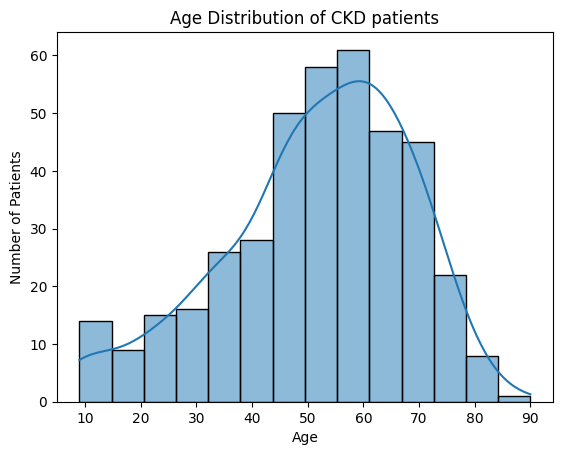

In [219]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(clean_dataset["age"], kde=True)
plt.title("Age Distribution of CKD patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

2) What is the average and median of age?

In [220]:
clean_dataset["age"].mean()

51.568375959079276

In [221]:
clean_dataset["age"].median()

54.0

3) How many patients have CKD in the dataset?

In [222]:
ckdpatients = (clean_dataset["classification"]==1).sum()

In [223]:
print("Number of CKD patients in the dataset are {}".format(ckdpatients))

Number of CKD patients in the dataset are 150


4) How many patients do not have CKD in the dataset?

In [224]:
notckdpatients = (clean_dataset["classification"]==0).sum()

In [225]:
print("Number of non-CKD patients in the dataset are {}".format(notckdpatients))

Number of non-CKD patients in the dataset are 250


5) Unusually young patients

In [226]:
clean_dataset["age"].min()

9.0

6) Unusually old patients

In [227]:
clean_dataset["age"].max()

90.0

7) Distribution of Blood pressure for CKD patients

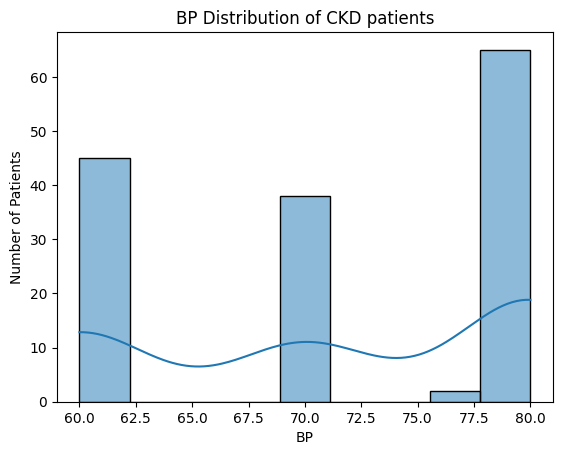

In [228]:
ckd_df = clean_dataset[clean_dataset["classification"] == 1].copy()
import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(ckd_df["bp"], kde=True)
plt.title("BP Distribution of CKD patients")
plt.xlabel("BP")
plt.ylabel("Number of Patients")
plt.show()

8) Mininum, Maximum, Mean and Median values of BP in CKD patients

In [229]:
ckd_df["bp"].mean()
ckd_df["bp"].median()
ckd_df["bp"].min()
ckd_df["bp"].max()
print("Minimum value of bp {}".format(ckd_df["bp"].min()))
print("Maximum value of bp {}".format(ckd_df["bp"].max()))
print("Mean value of bp {}".format(ckd_df["bp"].mean()))
print("Median value of bp {}".format(ckd_df["bp"].median()))

Minimum value of bp 60.0
Maximum value of bp 80.0
Mean value of bp 71.41958762886598
Median value of bp 70.0


# Univariate Analysis for Categorical columns

1) How many patients have anaemia?

In [230]:
an_df = (clean_dataset["ane"]==1).sum()
print(f"Number of Anaemia patients is {an_df}")

Number of Anaemia patients is 60


2) How many patients have pedal oedema?

In [231]:
pe_df = (clean_dataset["pe"]==1).sum()
print("Number of pedal oedema patients is:", (pe_df))

Number of pedal oedema patients is: 76


3) How many patients have normal vs abnormal red blood cells?

In [233]:
rbc_df = (clean_dataset["rbc"]==1).sum()
non_rbc_df = (clean_dataset["rbc"]==0).sum()
print("Normal rbc count patients:", rbc_df)
print("Abnormal rbc count patients:", non_rbc_df)

Normal rbc count patients: 353
Abnormal rbc count patients: 47


3.1 Bar plot comparing normal rbc patients and abnormal rbc patients

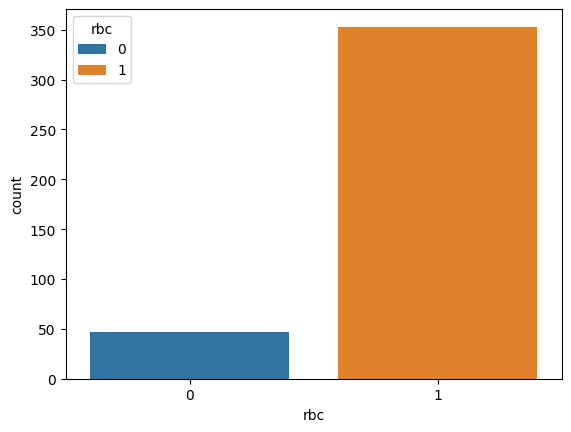

In [234]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=clean_dataset["rbc"], data=clean_dataset, hue="rbc")
plt.show()

4. How many patients have normal vs abnormal pus cells?

In [235]:
print("Normal pc patients:", (clean_dataset["pc"]==0).sum())
print("Abnormal pc patients:", (clean_dataset["pc"]==1).sum())

Normal pc patients: 76
Abnormal pc patients: 324


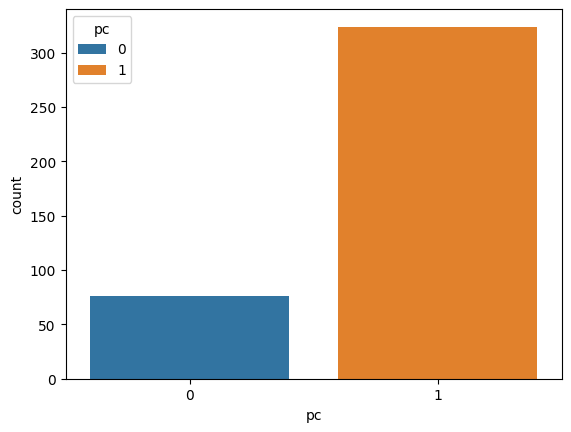

In [236]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=clean_dataset["pc"], data=clean_dataset, hue="pc")
plt.show()

5. How many patients have bacteria present vs absent?

In [238]:
print("Patients having Bacteria:", (clean_dataset["ba"]==1).sum())
print("Patients not having Bacteria:", (clean_dataset["ba"]==0).sum())

Patients having Bacteria: 22
Patients not having Bacteria: 378


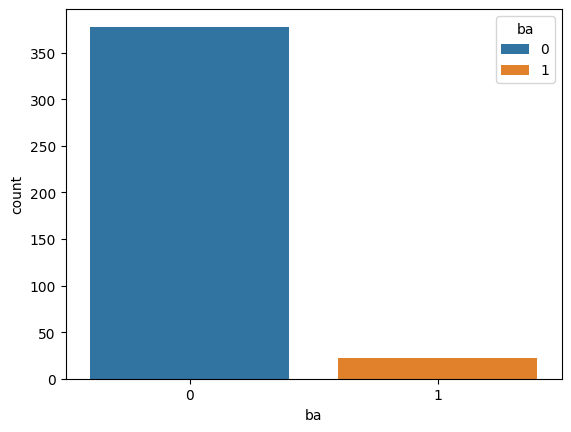

In [239]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=clean_dataset["ba"], data=clean_dataset, hue="ba")
plt.show()

6. How many patients have pus cell clumps present vs not present?

In [240]:
print("Patients having pus cell clumps:", (clean_dataset["pcc"]==1).sum())
print("Patients not having pus cell clumps:", (clean_dataset["pcc"]==0).sum())

Patients having pus cell clumps: 42
Patients not having pus cell clumps: 358


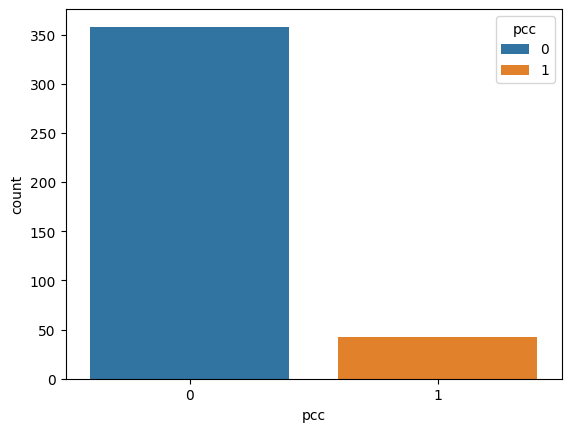

In [241]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=clean_dataset["pcc"], data=clean_dataset, hue="pcc")
plt.show()

7. How many patients are having hypertension?

In [242]:
print("Patients having hypertension:", (clean_dataset["htn"]==1).sum())
print("Patients not having hypertension:", (clean_dataset["htn"]==0).sum())

Patients having hypertension: 147
Patients not having hypertension: 253


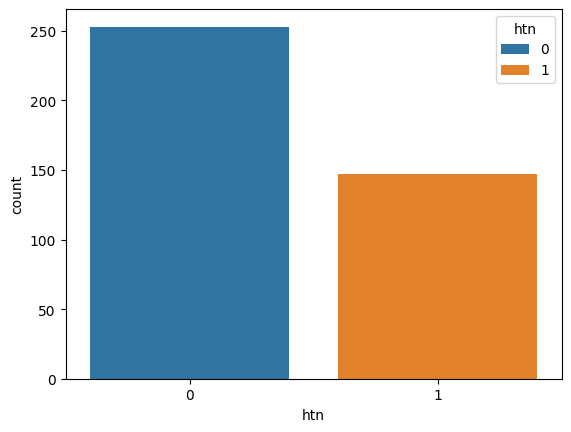

In [243]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=clean_dataset["htn"], data=clean_dataset, hue="htn")
plt.show()

8. Distribution of Diabetes status of all the patients

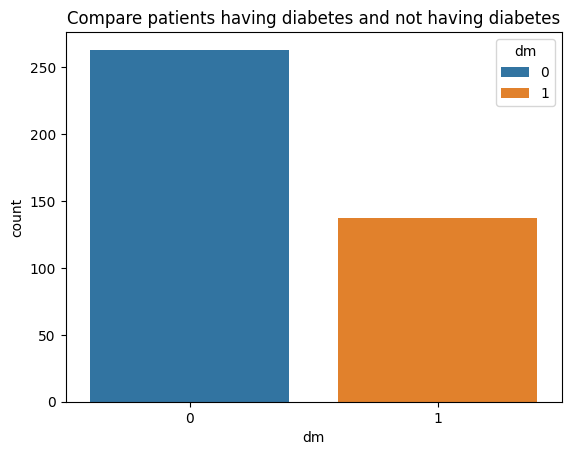

In [246]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=clean_dataset["dm"], data=clean_dataset, hue="dm")
plt.title("Compare patients having diabetes and not having diabetes")
plt.show()

9. How many patients have coronary artery disease?

In [247]:
print("Patients having coronary artery disease:", (clean_dataset["cad"]==1).sum())
print("Patients not having coronary artery disease:", (clean_dataset["cad"]==0).sum())

Patients having coronary artery disease: 34
Patients not having coronary artery disease: 366


9.1 patients having cad and not having cad - compare categories

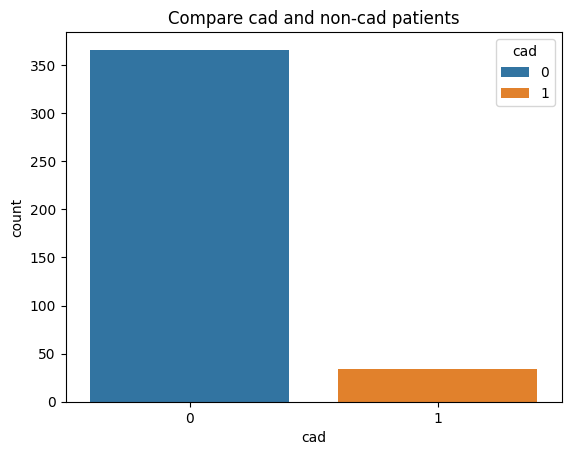

In [249]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=clean_dataset["cad"], data=clean_dataset, hue="cad")
plt.title("Compare cad and non-cad patients")
plt.show()

10. How many patients have good vs poor appetite?

In [250]:
print("Patients having good appetite:", (clean_dataset["appet"]==1).sum())
print("Patients having poor appetite:", (clean_dataset["appet"]==0).sum())

Patients having good appetite: 82
Patients having poor appetite: 318


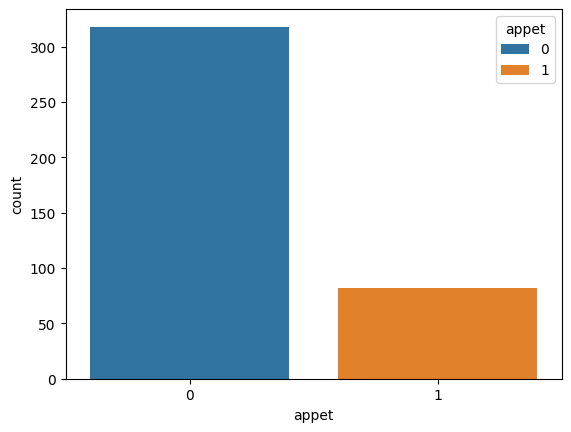

In [251]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=clean_dataset["appet"], data=clean_dataset, hue="appet")
plt.show()

11. How many patients have ckd and no-ckd in the dataset?

In [252]:
print("Patients having CKD:", (clean_dataset["classification"]==1).sum())
print("Patients having no CKD:", (clean_dataset["classification"]==0).sum())

Patients having CKD: 150
Patients having no CKD: 250


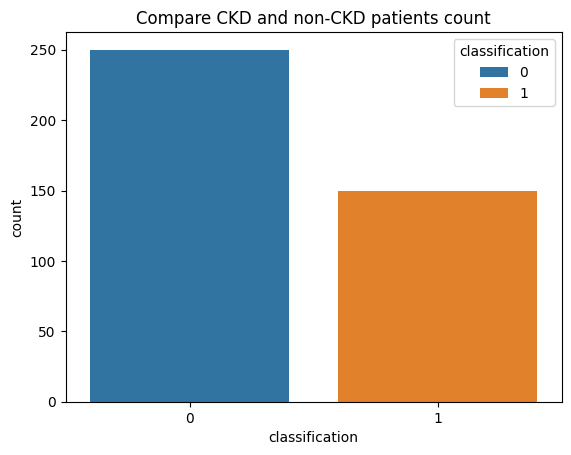

In [253]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=clean_dataset["classification"], data=clean_dataset, hue="classification")
plt.title("Compare CKD and non-CKD patients count")
plt.show()

Standard Normal Distribution - for 'bu' in CKD patients

In [254]:
def stdNBgraph(clean_dataset):
    import seaborn as sns 
    mean = clean_dataset.mean() 
    std = clean_dataset.std() 
    values = [] 
    # Calculate z-scores 
    for j in clean_dataset: 
        z_score = (j - mean) / std 
        values.append(z_score)

    # Plot the z-scores 
    sns.distplot(values, kde=True)
    print(sum(values)/len(values))
        

2.3684757858670008e-17


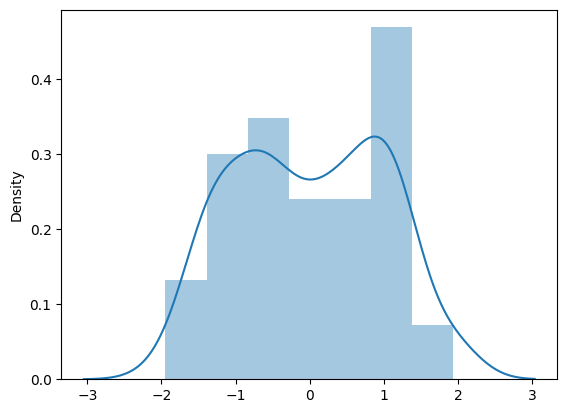

In [255]:
ckd_df = clean_dataset[clean_dataset["classification"] == 1].copy()
stdNBgraph(ckd_df["bu"])

# Percentile

In [256]:
ckd_df = clean_dataset[clean_dataset["classification"] == 1].copy()
ckdperl = np.percentile(ckd_df["age"], 60)
print("60% of CKD patients age are at or below this age: {}".format(ckdperl))

60% of CKD patients age are at or below this age: 51.0


# Bivariate Analysis

# Covariance

In [257]:
clean_dataset.cov(numeric_only = True)

,id,age,bp,sg,al,su,bgr,bu,sc,sod,...,pc,pcc,ba,htn,dm,cad,appet,pe,ane,classification
id,13366.666667,-364.479107,-326.175942,0.375005,-76.496963,-14.237235,-1946.499437,-1292.335602,-99.682295,269.756366,...,15.250627,-9.373434,-3.060150,-29.026316,-26.098997,-6.636591,-17.496241,-13.992481,-11.288221,46.992481
age,-364.479107,280.505971,29.325887,-0.016551,2.567445,1.855706,192.836161,127.644467,6.789406,-9.504495,...,-0.688647,0.819870,0.171668,3.192646,2.902421,1.096930,1.074879,0.636015,0.304129,-1.886649
bp,-326.175942,29.325887,119.847299,-0.011610,2.435765,0.951865,91.492052,73.370997,5.739803,-8.861353,...,-0.672403,0.237591,0.336292,1.384046,1.180186,0.289603,0.682970,0.178513,0.814020,-1.616348
sg,0.375005,-0.016551,-0.011610,0.000028,-0.003126,-0.000686,-0.093974,-0.051818,-0.003998,0.010728,...,0.000705,-0.000465,-0.000267,-0.000942,-0.000993,-0.000230,-0.000526,-0.000552,-0.000403,0.001803
al,-76.496963,2.567445,2.435765,-0.003126,1.618793,0.175833,20.628730,17.245642,1.136257,-2.896238,...,-0.267448,0.156111,0.106835,0.295867,0.228537,0.084109,0.170001,0.220339,0.128414,-0.369568
su,-14.237235,1.855706,0.951865,-0.000686,0.175833,0.160105,11.163677,3.035599,0.220175,-0.407078,...,-0.024517,0.020116,0.012163,0.074453,0.104290,0.037055,0.029252,0.028216,0.021666,-0.078075
bgr,-1946.499437,192.836161,91.492052,-0.093974,20.628730,11.163677,2118.668096,301.247307,21.303117,-69.727791,...,-5.249702,2.841607,1.227995,9.187343,11.694127,2.836300,4.174186,3.097798,2.455695,-10.394915
bu,-1292.335602,127.644467,73.370997,-0.051818,17.245642,3.035599,301.247307,915.749813,46.060466,-65.652790,...,-3.821331,1.858553,1.217722,7.110705,5.582335,2.194353,3.620360,3.721143,4.613037,-6.476208
sc,-99.682295,6.789406,5.739803,-0.003998,1.136257,0.220175,21.303117,46.060466,3.464078,-4.422809,...,-0.241263,0.105046,0.078781,0.449450,0.348853,0.128265,0.241421,0.235953,0.301740,-0.493126
sod,269.756366,-9.504495,-8.861353,0.010728,-2.896238,-0.407078,-69.727791,-65.652790,-4.422809,27.892306,...,0.607967,-0.357998,-0.186504,-1.063801,-0.918955,-0.280188,-0.562078,-0.554587,-0.562651,1.306750


# Correlation

In [258]:
clean_dataset.corr(numeric_only=True)

,id,age,bp,sg,al,su,bgr,bu,sc,sod,...,pc,pcc,ba,htn,dm,cad,appet,pe,ane,classification
id,1.000000,-0.188231,-0.257707,0.614634,-0.520040,-0.307760,-0.365773,-0.369382,-0.463247,0.441792,...,0.335825,-0.264142,-0.115955,-0.520089,-0.475106,-0.205575,-0.374394,-0.308120,-0.273096,0.838528
age,-0.188231,1.000000,0.159943,-0.187254,0.120485,0.276908,0.250142,0.251850,0.217805,-0.107452,...,-0.104680,0.159487,0.044903,0.394891,0.364727,0.234555,0.158776,0.096679,0.050791,-0.232392
bp,-0.257707,0.159943,1.000000,-0.200956,0.174874,0.217300,0.181567,0.221474,0.281701,-0.153265,...,-0.156370,0.070708,0.134574,0.261899,0.226890,0.094738,0.154342,0.041514,0.207980,-0.304594
sg,0.614634,-0.187254,-0.200956,1.000000,-0.465623,-0.324798,-0.386874,-0.324480,-0.407006,0.384928,...,0.340259,-0.286975,-0.221447,-0.369853,-0.396049,-0.155783,-0.246533,-0.266139,-0.213844,0.704728
al,-0.520040,0.120485,0.174874,-0.465623,1.000000,0.345385,0.352245,0.447915,0.479830,-0.431019,...,-0.535157,0.399749,0.367855,0.481724,0.378042,0.236745,0.330562,0.440893,0.282305,-0.599238
su,-0.307760,0.276908,0.217300,-0.324798,0.345385,1.000000,0.606141,0.250700,0.295646,-0.192634,...,-0.155995,0.163788,0.133168,0.385460,0.548554,0.331648,0.180861,0.179529,0.151450,-0.402543
bgr,-0.365773,0.250142,0.181567,-0.386874,0.352245,0.606141,1.000000,0.216273,0.248667,-0.286835,...,-0.290362,0.201133,0.116876,0.413481,0.534705,0.220677,0.224355,0.171340,0.149226,-0.465897
bu,-0.369382,0.251850,0.221474,-0.324480,0.447915,0.250700,0.216273,1.000000,0.817798,-0.410793,...,-0.321487,0.200095,0.176286,0.486768,0.388245,0.259690,0.295978,0.313058,0.426383,-0.441503
sc,-0.463247,0.217805,0.281701,-0.407006,0.479830,0.295646,0.248667,0.817798,1.000000,-0.449948,...,-0.330015,0.183881,0.185433,0.500248,0.394482,0.246802,0.320905,0.322751,0.453462,-0.546594
sod,0.441792,-0.107452,-0.153265,0.384928,-0.431019,-0.192634,-0.286835,-0.410793,-0.449948,1.000000,...,0.293073,-0.220846,-0.154705,-0.417269,-0.366210,-0.189996,-0.263300,-0.267340,-0.297988,0.510447


In [ ]:
#pairplot will provide graph of the dataset

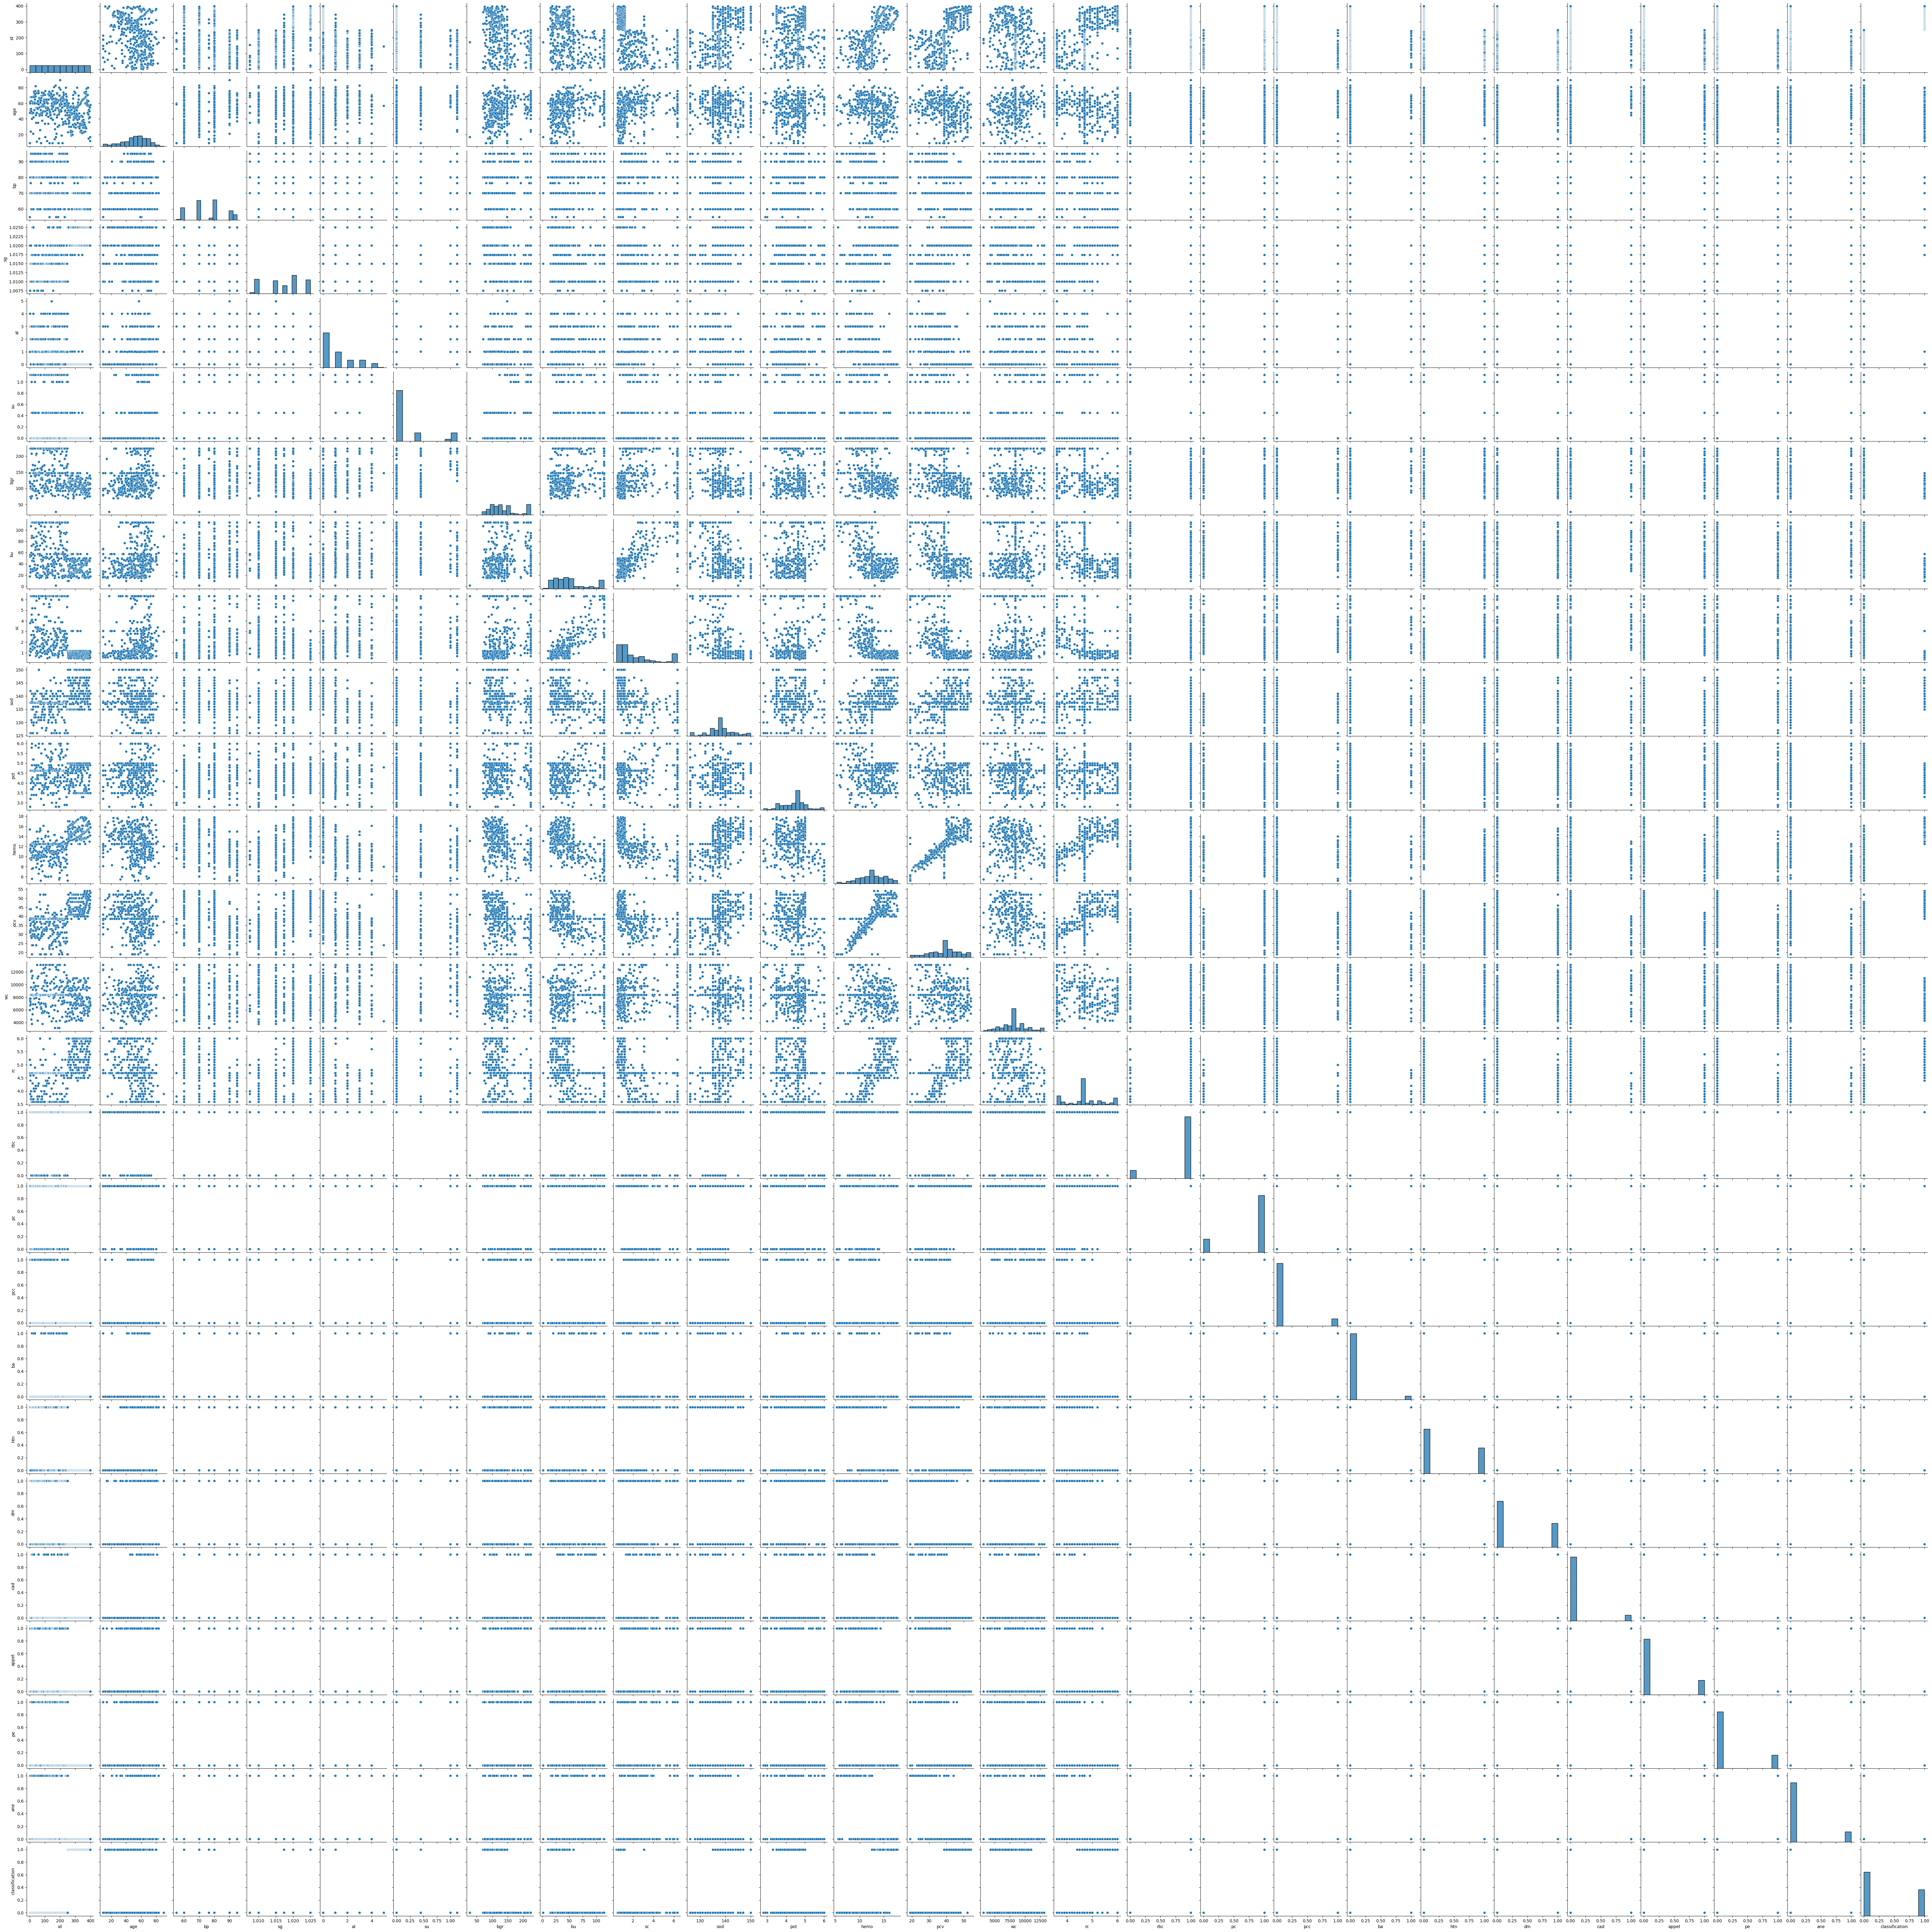

In [259]:
import seaborn as sns
import matplotlib.pyplot as plt
pair_plot = sns.pairplot(clean_dataset)
pair_plot.savefig("pairplot.png", dpi=300)
plt.show()                  

# Independent Sample - Unpaired Test - checking the association of 'age' with two classifications, 'ckd' and 'notckd'

In [260]:
clean_dataset[clean_dataset["classification"]==1]

,id,age,bp,sg,al,su,bgr,bu,sc,sod,...,pc,pcc,ba,htn,dm,cad,appet,pe,ane,classification
250,250.0,40.0,80.0,1.025,0.0,0.0,140.0,10.0,1.2,135.0,...,1,0,0,0,0,0,0,0,0,1
251,251.0,23.0,80.0,1.025,0.0,0.0,70.0,36.0,1.0,150.0,...,1,0,0,0,0,0,0,0,0,1
252,252.0,45.0,80.0,1.025,0.0,0.0,82.0,49.0,0.6,147.0,...,1,0,0,0,0,0,0,0,0,1
253,253.0,57.0,80.0,1.025,0.0,0.0,119.0,17.0,1.2,135.0,...,1,0,0,0,0,0,0,0,0,1
254,254.0,51.0,60.0,1.025,0.0,0.0,99.0,38.0,0.8,135.0,...,1,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,395.0,55.0,80.0,1.020,0.0,0.0,140.0,49.0,0.5,150.0,...,1,0,0,0,0,0,0,0,0,1
396,396.0,42.0,70.0,1.025,0.0,0.0,75.0,31.0,1.2,141.0,...,1,0,0,0,0,0,0,0,0,1
397,397.0,12.0,80.0,1.020,0.0,0.0,100.0,26.0,0.6,137.0,...,1,0,0,0,0,0,0,0,0,1
398,398.0,17.0,60.0,1.025,0.0,0.0,114.0,50.0,1.0,135.0,...,1,0,0,0,0,0,0,0,0,1


In [261]:
clean_dataset[clean_dataset["classification"]==0]

,id,age,bp,sg,al,su,bgr,bu,sc,sod,...,pc,pcc,ba,htn,dm,cad,appet,pe,ane,classification
0,0.0,48.0,80.0,1.020000,1.000000,0.000000,121.000000,36.000,1.200000,137.528754,...,1,0,0,1,1,0,0,0,0,0
1,1.0,9.0,55.0,1.020000,4.000000,0.000000,148.036517,18.000,0.800000,137.528754,...,1,0,0,0,0,0,0,0,0,0
2,2.0,62.0,80.0,1.010000,2.000000,1.125356,223.500000,53.000,1.800000,137.528754,...,1,0,0,0,1,0,1,0,1,0
3,3.0,48.0,70.0,1.007500,4.000000,0.000000,117.000000,56.000,3.800000,126.000000,...,0,1,0,1,0,0,1,1,1,0
4,4.0,51.0,80.0,1.010000,2.000000,0.000000,106.000000,26.000,1.400000,137.528754,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,245.0,48.0,95.0,1.017408,1.016949,0.450142,103.000000,79.000,5.300000,135.000000,...,1,0,0,1,0,1,1,0,0,0
246,246.0,48.0,95.0,1.015000,3.000000,0.000000,106.000000,113.875,6.331136,126.000000,...,1,1,0,1,0,1,0,0,1,0
247,247.0,54.0,90.0,1.025000,1.000000,0.000000,150.000000,18.000,1.200000,140.000000,...,0,0,0,0,0,0,1,1,1,0
248,248.0,59.0,70.0,1.010000,1.000000,1.125356,223.500000,55.000,1.700000,138.000000,...,0,0,0,1,1,1,0,0,0,0


# TTest

In [262]:
#Indpendent sample - unpaired tests
#Two groups and same condition
from scipy.stats import ttest_ind
ckd = clean_dataset[clean_dataset["classification"]==1]["age"]
notckd = clean_dataset[clean_dataset["classification"]==0]["age"]
ttest_ind(ckd, notckd)


TtestResult(statistic=-4.7667046357721, pvalue=2.6302895143616656e-06, df=398.0)

In [ ]:
#pvalue is 26%; similarity is less and difference is more between age and two classes of classification

# Distribution of CKD and non-CKD patients in the dataset

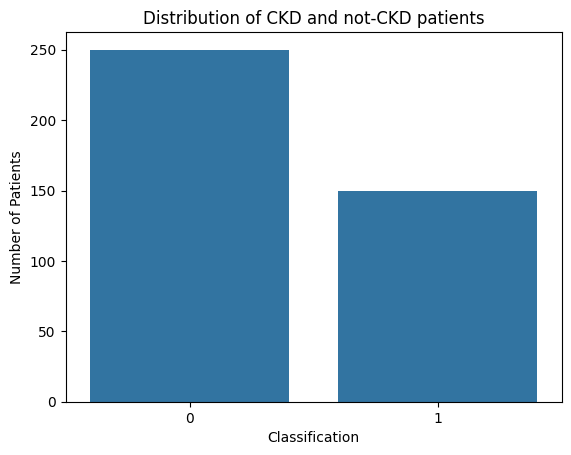

In [263]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(data = clean_dataset, x ='classification')
plt.title("Distribution of CKD and not-CKD patients")
plt.xlabel("Classification")
plt.ylabel("Number of Patients")
plt.show()

# How are serum creatinine levels distributed?

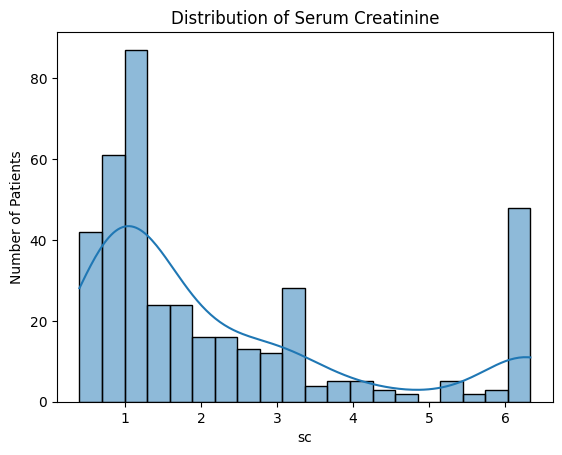

In [264]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(data = clean_dataset, x ='sc',bins = 20, kde=True)
plt.title("Distribution of Serum Creatinine")
plt.xlabel("sc")
plt.ylabel("Number of Patients")
plt.show()

# Does blood urea(bu) differ/have association between CKD and non-CKD patients?

In [266]:
#Indpendent sample - unpaired tests
#Two groups and same condition
from scipy.stats import ttest_ind
buckd = clean_dataset[clean_dataset["classification"]==1]["bu"]
bunotckd = clean_dataset[clean_dataset["classification"]==0]["bu"]
ttest_ind(buckd, bunotckd)


TtestResult(statistic=-9.816494237523528, pvalue=1.6364609205418168e-20, df=398.0)

In [ ]:
#Difference is more and similarities are less, as pvalue is 16%

# Does haemoglobin differ/have association between the two classes of classification?

In [267]:
#Indpendent sample - unpaired tests
#Two groups and same condition
from scipy.stats import ttest_ind
hckd = clean_dataset[clean_dataset["classification"]==1]["hemo"]
hnotckd = clean_dataset[clean_dataset["classification"]==0]["hemo"]
ttest_ind(hckd, hnotckd)


TtestResult(statistic=21.504380787565914, pvalue=1.268014431593429e-68, df=398.0)

In [ ]:
#Difference is more and similarities are less, as pvalue is 12%

# Is anaemia associated with ckd classifcation?

In [268]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.crosstab(clean_dataset['ane'], clean_dataset['classification'])

classification,0,1
ane,,
0,190,150
1,60,0


In [269]:
ct = pd.crosstab(clean_dataset['ane'], clean_dataset['classification'], normalize = 'index')*100

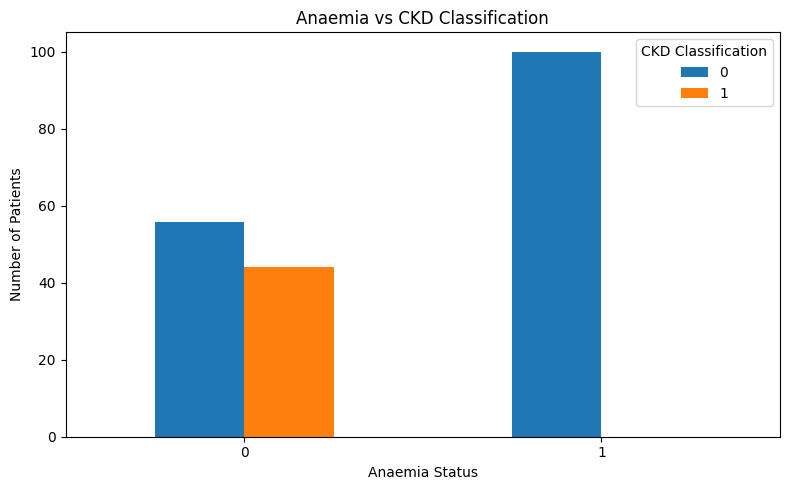

In [270]:
#Grouped Bar Chart for knowing the association of anaemia with ckd classification
import pandas as pd
import matplotlib.pyplot as plt

ct = pd.crosstab(clean_dataset['ane'], clean_dataset['classification'], normalize = 'index')*100
ct.plot(kind = 'bar', figsize = (8,5))
plt.title("Anaemia vs CKD Classification")
plt.xlabel("Anaemia Status")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.legend(title ='CKD Classification')
plt.tight_layout()
plt.show()

In [271]:
#check percentages to understand the association
#Create percentage table
percentage_table = pd.crosstab(clean_dataset['ane'], clean_dataset['classification'], normalize = 'index')*100
print(percentage_table.round(2).astype(str)+"%")

classification       0       1
ane                           
0               55.88%  44.12%
1               100.0%    0.0%


From the above percentage table, we can come to a conclusion that there is no direct association of anaemia with CKD classification

In [272]:
#Performing Chi-Square test of independence to test the association between two categorical variables
import pandas as pd
from scipy.stats import chi2_contingency

table = pd.crosstab(clean_dataset["ane"],clean_dataset["classification"])

chi2, p_value, dof, expected = chi2_contingency(table)
print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Expected Frequencies:\n", expected)


Chi-square statistic: 40.491503267973854
P-value: 1.9747291794838495e-10
Degrees of freedom: 1
Expected Frequencies:
 [[212.5 127.5]
 [ 37.5  22.5]]


# Hypothesis Testing
If pvalue is below 0.05: There is statistical significant association between diabetes status and CKD classification in the dataset
If pvalue is above or equal to 0.05: There is insufficient evidence of a statistical association between diabetes status and CKD classification in the dataset
From the above Chi-square Test, pvalue is 1.9747291794838495.., which is 19% approximately..
Result:
So we can conclude that Diabetes does not have statistical association with CKD.


# Is Diabetes status associated with CKD classification?

In [273]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.crosstab(clean_dataset['dm'], clean_dataset['classification'])

classification,0,1
dm,,
0,113,150
1,137,0


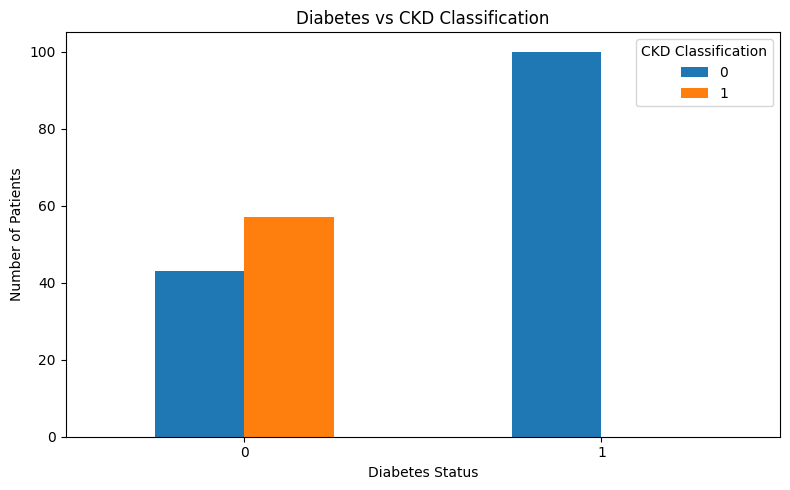

In [274]:
#Grouped Bar Chart for knowing the association of dm with ckd classification
import pandas as pd
import matplotlib.pyplot as plt

ct = pd.crosstab(clean_dataset['dm'], clean_dataset['classification'], normalize = 'index')*100
ct.plot(kind = 'bar', figsize = (8,5))
plt.title("Diabetes vs CKD Classification")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.legend(title ='CKD Classification')
plt.tight_layout()
plt.show()

In [275]:
#check percentages to understand the association
#Create percentage table
percentage_table = pd.crosstab(clean_dataset['dm'], clean_dataset['classification'], normalize = 'index')*100
print(percentage_table.round(2).astype(str)+"%")

classification       0       1
dm                            
0               42.97%  57.03%
1               100.0%    0.0%


In [ ]:
#From the above percentage table, we can conclude that there is no direct association with dm and CKD classification

In [276]:
#Performing Chi-Square test of independence to test the association between two categorical variables
import pandas as pd
from scipy.stats import chi2_contingency

table = pd.crosstab(clean_dataset["dm"],clean_dataset["classification"])

chi2, p_value, dof, expected = chi2_contingency(table)
print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Expected Frequencies:\n", expected)


Chi-square statistic: 122.59739298566973
P-value: 1.7082083994569608e-28
Degrees of freedom: 1
Expected Frequencies:
 [[164.375  98.625]
 [ 85.625  51.375]]


# Hypothesis Testing
If pvalue is below 0.05: There is significant association between diabetes status and CKD classification in the dataset
If pvalue is above or equal to 0.05: There is insufficient evidence of an association between diabetes status and CKD classification in the dataset
From the above Chi-square Test, pvalue is 1.7082083994569608.., which is 17% approximately..
Result:
So we can conclude that Diabetes does not have statistical association with CKD.


# Is Hypertension associated with CKD classification?

In [277]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.crosstab(clean_dataset["htn"],clean_dataset["classification"])

classification,0,1
htn,,
0,103,150
1,147,0


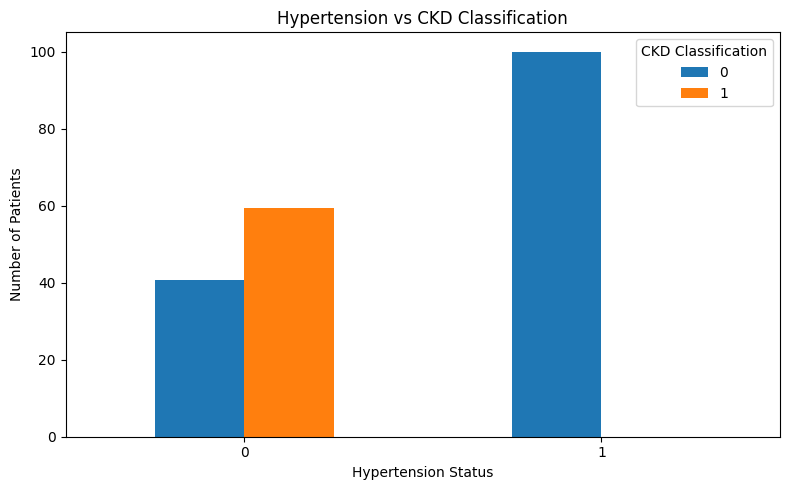

In [278]:
#Grouped Bar Chart for knowing the association of dm with ckd classification
import pandas as pd
import matplotlib.pyplot as plt

ct = pd.crosstab(clean_dataset['htn'], clean_dataset['classification'], normalize = 'index')*100
ct.plot(kind = 'bar', figsize = (8,5))
plt.title("Hypertension vs CKD Classification")
plt.xlabel("Hypertension Status")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.legend(title ='CKD Classification')
plt.tight_layout()
plt.show()

In [279]:
#check percentages to understand the association
#Create percentage table
percentage_table = pd.crosstab(clean_dataset['htn'], clean_dataset['classification'], normalize = 'index')*100
print(percentage_table.round(2).astype(str)+"%")

classification       0       1
htn                           
0               40.71%  59.29%
1               100.0%    0.0%


In [280]:
#From the above percentage table, we can conclude that there is no direct association with htn and CKD classification

In [281]:
#Performing Chi-Square test of independence to test the association between two categorical variables
import pandas as pd
from scipy.stats import chi2_contingency

table = pd.crosstab(clean_dataset["htn"],clean_dataset["classification"])

chi2, p_value, dof, expected = chi2_contingency(table)
print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Expected Frequencies:\n", expected)


Chi-square statistic: 136.92846835703978
P-value: 1.2500814473128787e-31
Degrees of freedom: 1
Expected Frequencies:
 [[158.125  94.875]
 [ 91.875  55.125]]


# Hypothesis Testing
If pvalue is below 0.05: There is significant association between diabetes status and CKD classification in the dataset
If pvalue is above or equal to 0.05: There is insufficient evidence of an association between diabetes status and CKD classification in the dataset
From the above Chi-square Test, pvalue is 1.2500814473128787.., which is 12% approximately..
Result:
So we can conclude that Hypertension does not have statistical association with CKD.


# Which Numerical features are strongly correlated with each other?

In [282]:
#Finding Strongly correlated features in the dataset
corr_matrix = clean_dataset.corr(numeric_only=True)

strong_corr = corr_matrix[(corr_matrix.abs()>0.7)&(corr_matrix.abs()<1.0)]
print(strong_corr)

                      id  age  bp        sg  al  su  bgr        bu        sc  \
id                   NaN  NaN NaN       NaN NaN NaN  NaN       NaN       NaN   
age                  NaN  NaN NaN       NaN NaN NaN  NaN       NaN       NaN   
bp                   NaN  NaN NaN       NaN NaN NaN  NaN       NaN       NaN   
sg                   NaN  NaN NaN       NaN NaN NaN  NaN       NaN       NaN   
al                   NaN  NaN NaN       NaN NaN NaN  NaN       NaN       NaN   
su                   NaN  NaN NaN       NaN NaN NaN  NaN       NaN       NaN   
bgr                  NaN  NaN NaN       NaN NaN NaN  NaN       NaN       NaN   
bu                   NaN  NaN NaN       NaN NaN NaN  NaN       NaN  0.817798   
sc                   NaN  NaN NaN       NaN NaN NaN  NaN  0.817798       NaN   
sod                  NaN  NaN NaN       NaN NaN NaN  NaN       NaN       NaN   
pot                  NaN  NaN NaN       NaN NaN NaN  NaN       NaN       NaN   
hemo                 NaN  NaN NaN       

# Strongly correlated result below:
sc-bu
bu-sc
pcv-hemo
hemo-pcv

# ANAVO

In [283]:
#ANAVO - Analysis of variance - Variance level between CKD and non-CKD patients
#Test whether the mean age differs between CKD and non-CKD patients

from scipy.stats import f_oneway

ckd = clean_dataset[clean_dataset['classification']==1]['age']
nonckd = clean_dataset[clean_dataset['classification']==0]['age']

f_stat, p_value = f_oneway(ckd, nonckd)

print("F-statistic:", f_stat)
print("P-value:", p_value)



F-statistic: 22.721473084691244
P-value: 2.6302895143616415e-06


#Interpretation of the result
p_value<0.05 - Evidence that mean of the age differs between CKD and non-CKD patients
p_value>0.05 - Insufficient evidence of a difference in the group means
Here, the p-value is 2.63028951436163.., so there is no evidence that the mean of age differs between CKD and non-CKD patients

Accept Null Hypothesis
Reject Alternate Hypothesis